# Finite number of presses case

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cpp_routines import *

In [2]:
# Here we run the above function
val = expected_truncated_reward_table(10, 10, 100, truncation=0.9)

In [3]:
# V(alpha, beta) for some sample time step T = 5
print(np.array_str(val[4], precision=4))

[[2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019]
 [3.069  2.7102 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019]
 [3.3826 2.9584 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019]
 [3.6001 3.2204 2.8749 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019]
 [3.75   3.4286 3.0902 2.8147 2.7019 2.7019 2.7019 2.7019 2.7019 2.7019]
 [3.8571 3.5859 3.2818 2.9906 2.7709 2.7019 2.7019 2.7019 2.7019 2.7019]
 [3.9375 3.7059 3.4364 3.1633 2.9163 2.7384 2.7019 2.7019 2.7019 2.7019]
 [4.     3.8    3.5606 3.3092 3.0703 2.86   2.7139 2.7019 2.7019 2.7019]
 [4.05   3.8756 3.6622 3.4313 3.2053 2.9977 2.8165 2.7019 2.7019 2.7019]
 [4.0909 3.9375 3.7466 3.5346 3.3216 3.1217 2.9404 2.7822 2.7019 2.7019]]


We see that if the number of fails is greater or equal to the number of successes it is always better to move on to the next button

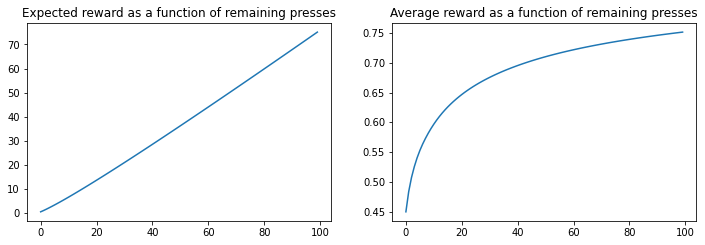

In [4]:
fig = plt.figure(figsize = (12,8))
ax = fig.add_subplot(221)
ax.set_title("Expected reward as a function of remaining presses")
ax.plot(val[:,0,0]);

val_avg = np.copy(val[:,0,0])
val_avg = val_avg/np.arange(1,len(val_avg)+1)

ax = fig.add_subplot(222)
ax.set_title("Average reward as a function of remaining presses")
ax.plot(val_avg);

In [5]:
# We have coded up a special C++ function that finds the minimal number of remaining presses
# For which it is more optimal to leave the current button and explore further
# For given number of wins and fails
# If no such number exists for the given process duration, the function returns 0

trans_table = optimal_truncated_transition_table(10, 10, 200, truncation=0.9)
print(trans_table)

[[  1   1   1   1   1   1   1   1   1   1]
 [  0   6   1   1   1   1   1   1   1   1]
 [  0   0   5   1   1   1   1   1   1   1]
 [  0   0  26   4   1   1   1   1   1   1]
 [  0   0 122  12   4   2   1   1   1   1]
 [  0   0   0  30   8   3   2   1   1   1]
 [  0   0   0  71  16   7   3   2   1   1]
 [  0   0   0 181  30  12   6   3   2   1]
 [  0   0   0   0  53  19   9   5   3   2]
 [  0   0   0   0  96  29  14   8   5   3]]


Here we experimentally test the optimal policy we have derived earlier.

The run_bernoulli_trials is run from C++ library.

In [6]:
run_time = 40
number_of_runs = 10000
button_truncation = 0.9
policy_truncation = 1.0

rewards = run_truncated_bernoulli_trials(run_time, number_of_runs, button_truncation=button_truncation,
                                                                   policy_truncation=policy_truncation)

print("The individual run length is: " + str(run_time))
print("The number of runs is: " + str(number_of_runs))
print("The theoretical reward is: " + str(val[run_time-1, 0, 0]))
print("The mean reward is: " + str(np.mean(rewards)))
print("The deviation is: " + str(np.std(rewards)))
print("The deviation of the mean is: " + str(np.std(rewards)/pow(len(rewards), 0.5)))

The individual run length is: 40
The number of runs is: 10000
The theoretical reward is: 27.742895824821716
The mean reward is: 27.294
The deviation is: 5.52017789568416
The deviation of the mean is: 0.0552017789568416


Here we inspect aspects of individual instances of the optimal policy we have derived earlier.

The record_full_bernoulli_trials is run from C++ library.

In [7]:
run_time = 40
number_of_runs = 10000
button_truncation = 0.9
policy_truncation = 0.9

trial_record = record_full_truncated_bernoulli_trials(run_time, number_of_runs, button_truncation=button_truncation,
                                                                                policy_truncation=policy_truncation)

The average number of buttons explored is 6.2318
Out of 10000 runs in total in 9341 runs (or 93.41%) the last button contributed the most
The average contribution of the button with the largest contribution is 84.07 %


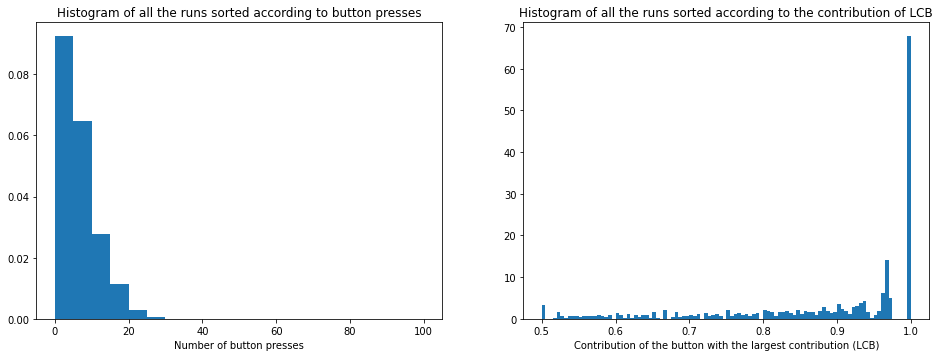

In [8]:
#Total number of button pressed
num_presses = np.max(trial_record[:,:,0], axis=1)
#Total number of buttons
num_buttons = np.max(trial_record[:,:,0], axis=1)+1
#Index of the button with largest contribution
max_button = trial_record[np.arange(len(trial_record)),
                          np.argmax(trial_record[:,:,1], axis=1),0]
#Number of runs where the final button was the button with the largest contribution
num_last_largest_contr = np.count_nonzero(num_presses==max_button)
#Ratio of largest button contribution to total contribution
top_button_to_all = np.max(trial_record[:,:,1], axis=1)/np.sum(trial_record[:,:,3], axis=1)

print("The average number of buttons explored is " + str(np.sum(num_buttons)/len(num_buttons)))
print("Out of " + str(number_of_runs) + " runs in total in " + str(num_last_largest_contr) + 
            " runs (or " + "%.2f" % (100*num_last_largest_contr/number_of_runs) + 
              "%) the last button contributed the most")
print("The average contribution of the button with the largest contribution is " + 
          "%4.2f" % (100*np.mean(top_button_to_all)) + " %")

fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(221)
ax.set_title("Histogram of all the runs sorted according to button presses")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons, density=True, bins=20, range=(0, 100));

ax = fig.add_subplot(222)
ax.set_title("Histogram of all the runs sorted according to the contribution of LCB")
ax.set_xlabel("Contribution of the button with the largest contribution (LCB)")
ax.hist(top_button_to_all, density=True, bins=100, range=(0.5,1));